# Laporan Proyek Akhir Mata Kuliah Probabilitas dan Statistika
## "Analisis dan Pengelompokan Karakteristik Keterlambatan Penerbangan Berdasarkan Durasi Keterlambatan dan Jarak Tempuh Menggunakan Metode K-Means"

---

### **Informasi Proyek**
* **Kelas / Kelompok:** 3TI A — Kelompok 3
* **Konsentrasi Bidang TI:** Jaringan / IoT - *Open Source & Cloud Networking* (OSCN)
* **Program Studi:** Sarjana Terapan Teknik Informatika, Politeknik Caltex Riau
* **Dosen Pengampu:** Mona Elviyenti, S.Si., M.Si.

### **Anggota Tim Peneliti:**
1. **Hanif Andika Hizamil Putra** (NIM: 2455301079)
2. **Yuma Wisesa Jigme** (NIM: 2455301199)
3. **Aditya Cahyo Oktavian** (NIM: 2455301008)
4. **Arkan Fawwaz Safii** (NIM: 2455301031)

---

In [7]:
# ==========================================
# KHUSUS GOOGLE COLAB / JUPYTER BARU:
# Instal pustaka python-calamine untuk membaca Excel raksasa (100MB) dalam hitungan detik
# ==========================================
!pip install -q python-calamine


In [8]:
# ==========================================
# 0. IMPORT LIBRARY DAN KONFIGURASI VISUAL
# ==========================================
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')

# Konfigurasi gaya visualisasi profesional
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['figure.dpi'] = 120

print('✅ Seluruh pustaka (libraries) berhasil diimpor dengan konfigurasi visual aktif.')


✅ Seluruh pustaka (libraries) berhasil diimpor dengan konfigurasi visual aktif.


### **1. Memuat Dataset dan Menampilkan Sampel Data Awal (100 Baris)**

Tahap awal analisis dimulai dengan memuat dataset operasional penerbangan dari berkas lokal `3TIA_03_FlightDelay.xlsx`.

* **Optimasi Kinerja:** Mengingat ukuran berkas yang sangat besar (sekitar 100MB), pemuatan data menggunakan pustaka berkinerja tinggi `python-calamine` sebagai *engine* utama guna menghemat waktu eksekusi.
* **Verifikasi Struktur:** Menampilkan dimensi keseluruhan dataset mentah beserta pratinjau 100 baris pertama untuk memahami struktur awal atribut data.

In [9]:
# ==========================================
# 1. LOAD DATASET & PRATINJAU 100 SAMPEL DATA
# ==========================================
try:
    import python_calamine
    df_raw = pd.read_excel('3TIA_03_FlightDelay.xlsx', engine='calamine')
    print('✅ Berkas berhasil dibaca menggunakan engine calamine.')
except (ImportError, ModuleNotFoundError):
    print('⚠️ Modul python_calamine belum terpasang. Membaca dengan engine standar...')
    df_raw = pd.read_excel('3TIA_03_FlightDelay.xlsx')

print(f'Dimensi dataset mentah: {df_raw.shape[0]:,} baris x {df_raw.shape[1]} kolom')
print(f'Daftar kolom yang tersedia:\n{df_raw.columns.tolist()}\n')

df_sample_100 = df_raw.head(100)
print('Pratinjau 10 sampel pertama dari 100 baris sampel data (menampilkan 6 kolom representatif):')

# Memformat tampilan tabel sampel agar kompatibel di semua tema Chrome (Dark/Light)
styled_sample = (
    df_sample_100[['FL_DATE', 'OP_CARRIER', 'ORIGIN', 'DEST', 'ARR_DELAY', 'DISTANCE']].head(10).style
    .set_caption("TABEL 1. PRATINJAU 10 SAMPEL BARIS DATA UTAMA")
    .set_properties(**{
        'text-align': 'center',
        'font-size': '13px',
        'padding': '10px 14px',
        'color': '#0f172a'  # Teks gelap agar selalu terbaca
    })
    .set_table_styles([
        {'selector': 'caption', 'props': [
            ('caption-side', 'top'),
            ('font-size', '15px'),
            ('font-weight', '700'),
            ('margin-bottom', '12px'),
            ('color', '#0284c7'),
            ('text-align', 'left')
        ]},
        {'selector': 'th', 'props': [
            ('background-color', '#0f172a'),
            ('color', '#ffffff'),
            ('font-weight', '700'),
            ('padding', '11px 16px'),
            ('border', '1px solid #334155')
        ]},
        {'selector': 'tbody tr:nth-child(odd) td', 'props': [
            ('background-color', '#ffffff'),
            ('border-bottom', '1px solid #e2e8f0')
        ]},
        {'selector': 'tbody tr:nth-child(even) td', 'props': [
            ('background-color', '#f8fafc'),
            ('border-bottom', '1px solid #e2e8f0')
        ]},
        {'selector': 'tbody tr:hover td', 'props': [
            ('background-color', '#f0f9ff')
        ]}
    ])
    .hide(axis='index')
)

display(styled_sample)

✅ Berkas berhasil dibaca menggunakan engine calamine.
Dimensi dataset mentah: 1,048,575 baris x 27 kolom
Daftar kolom yang tersedia:
['FL_DATE', 'OP_CARRIER', 'OP_CARRIER_FL_NUM', 'ORIGIN', 'DEST', 'CRS_DEP_TIME', 'DEP_TIME', 'DEP_DELAY', 'TAXI_OUT', 'WHEELS_OFF', 'WHEELS_ON', 'TAXI_IN', 'CRS_ARR_TIME', 'ARR_TIME', 'ARR_DELAY', 'CANCELLED', 'CANCELLATION_CODE', 'DIVERTED', 'CRS_ELAPSED_TIME', 'ACTUAL_ELAPSED_TIME', 'AIR_TIME', 'DISTANCE', 'CARRIER_DELAY', 'WEATHER_DELAY', 'NAS_DELAY', 'SECURITY_DELAY', 'LATE_AIRCRAFT_DELAY']

Pratinjau 10 sampel pertama dari 100 baris sampel data (menampilkan 6 kolom representatif):


FL_DATE,OP_CARRIER,ORIGIN,DEST,ARR_DELAY,DISTANCE
01-01-2018,UA,EWR,DEN,-23.000000,1605
01-01-2018,UA,LAS,SFO,-24.000000,414
01-01-2018,UA,SNA,DEN,-13.000000,846
01-01-2018,UA,RSW,ORD,-2.000000,1120
01-01-2018,UA,ORD,ALB,14.000000,723
01-01-2018,UA,ORD,OMA,-11.000000,416
01-01-2018,UA,IAH,LAS,-16.000000,1222
01-01-2018,UA,DEN,CID,-19.000000,692
01-01-2018,UA,SMF,EWR,-2.000000,2500
01-01-2018,UA,RIC,DEN,-17.000000,1482


### **2. Seleksi Kolom Utama dan Pembersihan Data (*Data Cleaning*)**

Untuk menjaga fokus analisis sesuai dengan rumusan masalah penelitian, dilakukan ekstraksi terhadap tiga variabel utama berikut:
1. **`ARR_DELAY`** : Durasi keterlambatan waktu tiba di bandara tujuan (dalam satuan menit).
2. **`DEP_DELAY`** : Durasi keterlambatan waktu keberangkatan dari bandara asal (dalam satuan menit).
3. **`DISTANCE`**  : Jarak tempuh antar-bandara dalam rute penerbangan (dalam satuan mil).

**Prosedur Pembersihan:**
* Seluruh baris data yang mengandung nilai kosong (*missing values/NaN*) pada ketiga kolom target dihapus menggunakan metode `.dropna()`.
* Tipe data dikonversi secara eksplisit ke dalam bentuk numerik presisi tinggi (*float*) untuk memastikan konsistensi dalam perhitungan statistik berikutnya.

In [10]:
# ==========================================
# 2. SELEKSI 3 KOLOM UTAMA & PEMBERSIHAN DATA
# ==========================================
# Mengambil seluruh baris dari 3 variabel utama
df_clean = df_raw[['ARR_DELAY', 'DEP_DELAY', 'DISTANCE']].dropna().copy()

# Memastikan tipe data numerik float
df_clean['ARR_DELAY'] = df_clean['ARR_DELAY'].astype(float)
df_clean['DEP_DELAY'] = df_clean['DEP_DELAY'].astype(float)
df_clean['DISTANCE'] = df_clean['DISTANCE'].astype(float)

print(f'Jumlah data mentah sebelum pembersihan : {len(df_raw):,} baris')
print(f'Jumlah data bersih siap analisis (N)   : {len(df_clean):,} baris')
print(f'Jumlah data bernilai kosong (NaN)      : {df_clean.isna().sum().sum()} nilai')
print('\n5 Baris Teratas Dataset Bersih:')

# Memformat visualisasi tabel dataset bersih agar kompatibel di semua tema Chrome (Dark/Light)
styled_clean = (
    df_clean.head(5).style
    .set_caption("TABEL 1.1 DATASET BERSIH SIAP ANALISIS (5 BARIS PERTAMA)")
    .set_properties(**{
        'text-align': 'right',
        'font-size': '13px',
        'font-family': 'monospace',
        'padding': '10px 14px',
        'color': '#0f172a'  # Teks gelap kontras tinggi
    })
    .set_table_styles([
        {'selector': 'caption', 'props': [
            ('caption-side', 'top'),
            ('font-size', '15px'),
            ('font-weight', '700'),
            ('margin-bottom', '12px'),
            ('color', '#0284c7'),
            ('text-align', 'left')
        ]},
        {'selector': 'th', 'props': [
            ('background-color', '#0f172a'),
            ('color', '#ffffff'),
            ('font-weight', '700'),
            ('padding', '11px 16px'),
            ('border', '1px solid #334155'),
            ('text-align', 'center')
        ]},
        {'selector': 'tbody tr:nth-child(odd) td', 'props': [
            ('background-color', '#ffffff'),
            ('border-bottom', '1px solid #e2e8f0')
        ]},
        {'selector': 'tbody tr:nth-child(even) td', 'props': [
            ('background-color', '#f8fafc'),
            ('border-bottom', '1px solid #e2e8f0')
        ]},
        {'selector': 'tbody tr:hover td', 'props': [
            ('background-color', '#f0f9ff')
        ]}
    ])
    .hide(axis='index')
)

display(styled_clean)

Jumlah data mentah sebelum pembersihan : 1,048,575 baris
Jumlah data bersih siap analisis (N)   : 1,018,813 baris
Jumlah data bernilai kosong (NaN)      : 0 nilai

5 Baris Teratas Dataset Bersih:


ARR_DELAY,DEP_DELAY,DISTANCE
-23.000000,-5.000000,1605.000000
-24.000000,-8.000000,414.000000
-13.000000,-5.000000,846.000000
-2.000000,6.000000,1120.000000
14.000000,20.000000,723.000000


### **3. Visualisasi Sebaran Lengkap 3 Variabel & Murni Statistika Deskriptif**

Visualisasi grafis di bawah ini dirancang untuk memberikan pemahaman intuitif mengenai sebaran frekuensi data:
* **Histogram & *Kernel Density Estimation* (KDE):** Digunakan untuk mengidentifikasi konsentrasi data, mendeteksi kemiringan distribusi (*skewness*), serta melihat titik puncak frekuensi pada durasi keterlambatan (`ARR_DELAY` & `DEP_DELAY`) dan jarak tempuh (`DISTANCE`).

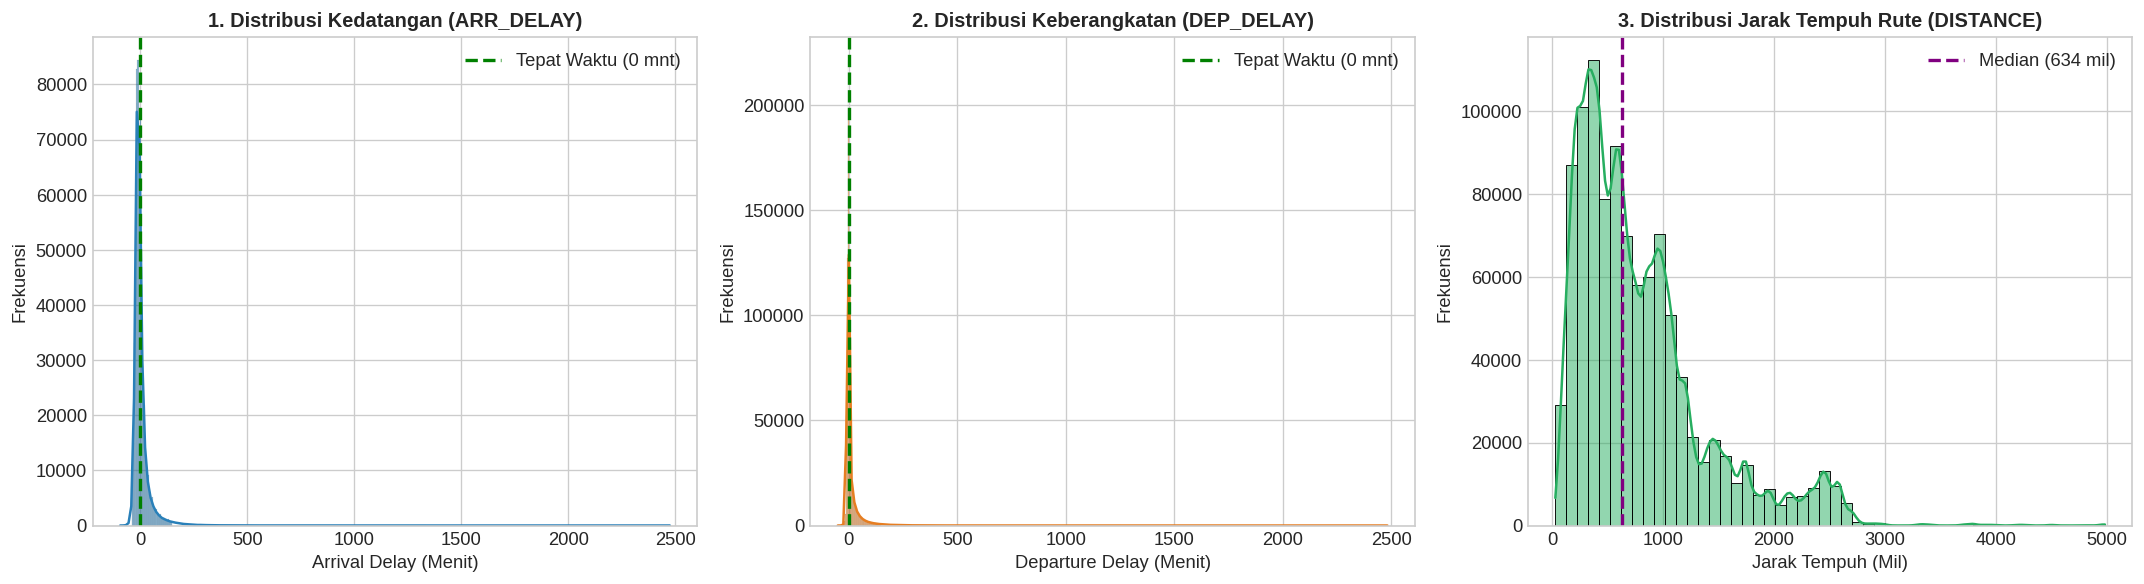

In [11]:
# ==============================================================================
# VISUALISASI SEBARAN LENGKAP 3 VARIABEL UTAMA
# Variabel: ARR_DELAY (Kedatangan), DEP_DELAY (Keberangkatan), DISTANCE (Jarak)
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

# Konfigurasi gaya visualisasi standar publikasi
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.patch.set_facecolor('#ffffff')

# 1. Histogram & Kurva KDE: Keterlambatan Kedatangan (ARR_DELAY)
sns.histplot(df_clean['ARR_DELAY'], bins=60, kde=True, ax=axes[0], color='#2980b9', binrange=(-40, 150))
axes[0].axvline(0, color='green', linestyle='--', linewidth=2, label='Tepat Waktu (0 mnt)')
axes[0].set_title('1. Distribusi Kedatangan (ARR_DELAY)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Arrival Delay (Menit)')
axes[0].set_ylabel('Frekuensi')
axes[0].legend()

# 2. Histogram & Kurva KDE: Keterlambatan Keberangkatan (DEP_DELAY)
sns.histplot(df_clean['DEP_DELAY'], bins=60, kde=True, ax=axes[1], color='#e67e22', binrange=(-30, 150))
axes[1].axvline(0, color='green', linestyle='--', linewidth=2, label='Tepat Waktu (0 mnt)')
axes[1].set_title('2. Distribusi Keberangkatan (DEP_DELAY)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Departure Delay (Menit)')
axes[1].set_ylabel('Frekuensi')
axes[1].legend()

# 3. Histogram & Kurva KDE: Jarak Tempuh Rute (DISTANCE)
sns.histplot(df_clean['DISTANCE'], bins=50, kde=True, ax=axes[2], color='#27ae60')
axes[2].axvline(634, color='purple', linestyle='--', linewidth=2, label='Median (634 mil)')
axes[2].set_title('3. Distribusi Jarak Tempuh Rute (DISTANCE)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Jarak Tempuh (Mil)')
axes[2].set_ylabel('Frekuensi')
axes[2].legend()

plt.tight_layout()
plt.show()

### **4. Analisis Statistika Deskriptif Lengkap**

Bagian ini menyajikan komputasi parameter statistik formal untuk mengevaluasi karakteristik matematis dari ketiga variabel utama:
* **Ukuran Pemusatan Data (*Measures of Central Tendency*):** Mean (Rata-rata), Median (Nilai Tengah), dan Modus.
* **Ukuran Penyebaran Data (*Measures of Dispersion*):** Standar Deviasi, Varians, Minimum, Kuartil (Q1, Q2, Q3), Maksimum, dan *Interquartile Range* (IQR).
* **Bentuk Distribusi Data:** *Skewness* (kemiringan kurva) dan *Kurtosis* (keruncingan kurva) untuk menguji normalitas sebaran data.

In [12]:
# ==============================================================================
# ANALISIS STATISTIKA DESKRIPTIF LENGKAP (STYLISH & DARK/LIGHT MODE FRIENDLY)
# ==============================================================================
stat_desc = {}
for col in ['ARR_DELAY', 'DEP_DELAY', 'DISTANCE']:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    modus = df_clean[col].mode()[0]

    stat_desc[col] = {
        'Mean (Rata-rata)': df_clean[col].mean(),
        'Median': df_clean[col].median(),
        'Modus': modus,
        'Standar Deviasi': df_clean[col].std(),
        'Varians': df_clean[col].var(),
        'Min': df_clean[col].min(),
        'Q1 (Kuartil 1)': q1,
        'Q3 (Kuartil 3)': q3,
        'Maksimum': df_clean[col].max(),
        'IQR (Rentang Antarkuartil)': iqr,
        'Skewness': df_clean[col].skew(),
        'Kurtosis': df_clean[col].kurtosis()
    }

df_stat = pd.DataFrame(stat_desc)

# Memformat visualisasi tabel agar kompatibel di semua tema chrome (Dark/Light)
styled_stat = (
    df_stat.round(3).style
    .set_caption("TABEL 2. PARAMETER STATISTIKA DESKRIPTIF LENGKAP")
    .set_properties(**{
        'text-align': 'right',
        'font-size': '13px',
        'font-family': 'monospace',
        'padding': '10px 14px',
        'color': '#0f172a' # Teks gelap kontras tinggi untuk sel data
    })
    .set_table_styles([
        {'selector': 'caption', 'props': [
            ('caption-side', 'top'),
            ('font-size', '15px'),
            ('font-weight', '700'),
            ('margin-bottom', '12px'),
            ('color', '#0284c7'),
            ('text-align', 'left')
        ]},
        {'selector': 'th', 'props': [
            ('background-color', '#0f172a'),
            ('color', '#ffffff'),
            ('font-weight', '700'),
            ('padding', '11px 16px'),
            ('text-align', 'center'),
            ('border', '1px solid #334155')
        ]},
        {'selector': 'th.row_heading', 'props': [
            ('background-color', '#1e293b'),
            ('color', '#ffffff'),
            ('text-align', 'left'),
            ('font-weight', '600')
        ]},
        {'selector': 'tbody tr:nth-child(odd) td', 'props': [
            ('background-color', '#ffffff'),
            ('border-bottom', '1px solid #e2e8f0')
        ]},
        {'selector': 'tbody tr:nth-child(even) td', 'props': [
            ('background-color', '#f8fafc'),
            ('border-bottom', '1px solid #e2e8f0')
        ]},
        {'selector': 'tbody tr:hover td', 'props': [
            ('background-color', '#f0f9ff')
        ]}
    ])
)

display(styled_stat)

,ARR_DELAY,DEP_DELAY,DISTANCE
Mean (Rata-rata),3.526000,9.629000,796.560000
Median,-7.000000,-2.000000,634.000000
Modus,-11.000000,-5.000000,337.000000
Standar Deviasi,48.304000,45.773000,591.774000
Varians,2333.323000,2095.188000,350196.380000
Min,-94.000000,-51.000000,31.000000
Q1 (Kuartil 1),-16.000000,-6.000000,361.000000
Q3 (Kuartil 3),7.000000,6.000000,1034.000000
Maksimum,2475.000000,2482.000000,4983.000000
IQR (Rentang Antarkuartil),23.000000,12.000000,673.000000


### **5. Visualisasi Murni Statistika Deskriptif (Deteksi Pencilan)**

Penggunaan grafik **Boxplot** secara murni bertujuan untuk mendeteksi keberadaan pencilan (*outliers*) ekstrem pada durasi keterlambatan dan rentang jarak tempuh penerbangan. Analisis pencilan ini sangat penting untuk mendeteksi anomali operasional penerbangan.

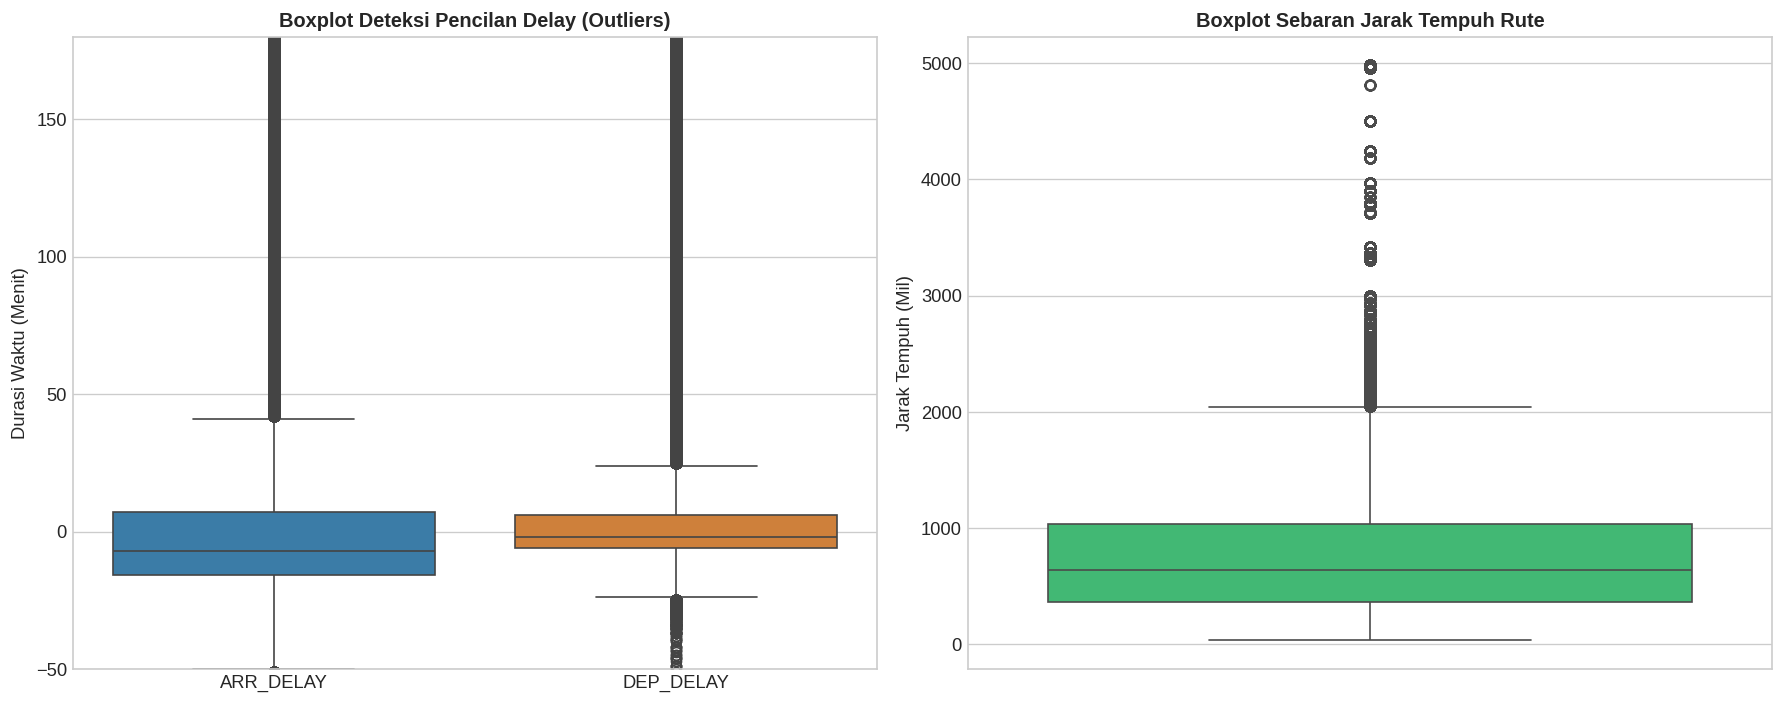

In [13]:
# ==============================================================================
# VISUALISASI BOXPLOT: DETEKSI OUTLIERS MURNI
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.patch.set_facecolor('#ffffff')

# 1. Boxplot Deteksi Pencilan Delay
sns.boxplot(data=df_clean[['ARR_DELAY', 'DEP_DELAY']], ax=axes[0], palette=['#2980b9', '#e67e22'])
axes[0].set_title('Boxplot Deteksi Pencilan Delay (Outliers)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Durasi Waktu (Menit)')
axes[0].set_ylim(-50, 180)

# 2. Boxplot Sebaran Jarak Tempuh Rute
sns.boxplot(y=df_clean['DISTANCE'], ax=axes[1], color='#2ecc71')
axes[1].set_title('Boxplot Sebaran Jarak Tempuh Rute', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Jarak Tempuh (Mil)')

plt.tight_layout()
plt.show()

### **6. Standarisasi, Analisis Korlasi, dan K-Means Clustering**

Tahapan pemodelan statistik non-parametrik menggunakan algoritma klasterisasi *unsupervised learning* K-Means:
1. **Standarisasi Skala:** Atribut `DISTANCE` (satuan mil) dan `ARR_DELAY` (satuan menit) ditransformasikan menggunakan `StandardScaler` agar memiliki skala seragam dengan rata-rata 0 dan varians 1, menghindari bias jarak geometris.
2. **Metode Elbow:** Menganalisis nilai *Within-Cluster Sum of Squares* (WCSS) pada berbagai nilai $k$ untuk memvalidasi jumlah klaster optimal ($k=3$).
3. **Klasterisasi K-Means:** Mengelompokkan seluruh data penerbangan ke dalam 3 profil karakteristik fungsional utama.

Klaster,Jumlah Data,Centroid Distance (Mil),Centroid ARR_DELAY (Menit),Karakteristik Operasional
Klaster 0,"172,783 (16.96%)",1848.53,-5.61,Rute Jarak Jauh / Transkontinental On-Time
Klaster 1,"812,011 (79.70%)",577.27,-2.18,Rute Pendek-Menengah Reguler On-Time
Klaster 2,"34,019 (3.34%)",681.10,186.68,Kejadian Krisis / Delay Operasional Ekstrem


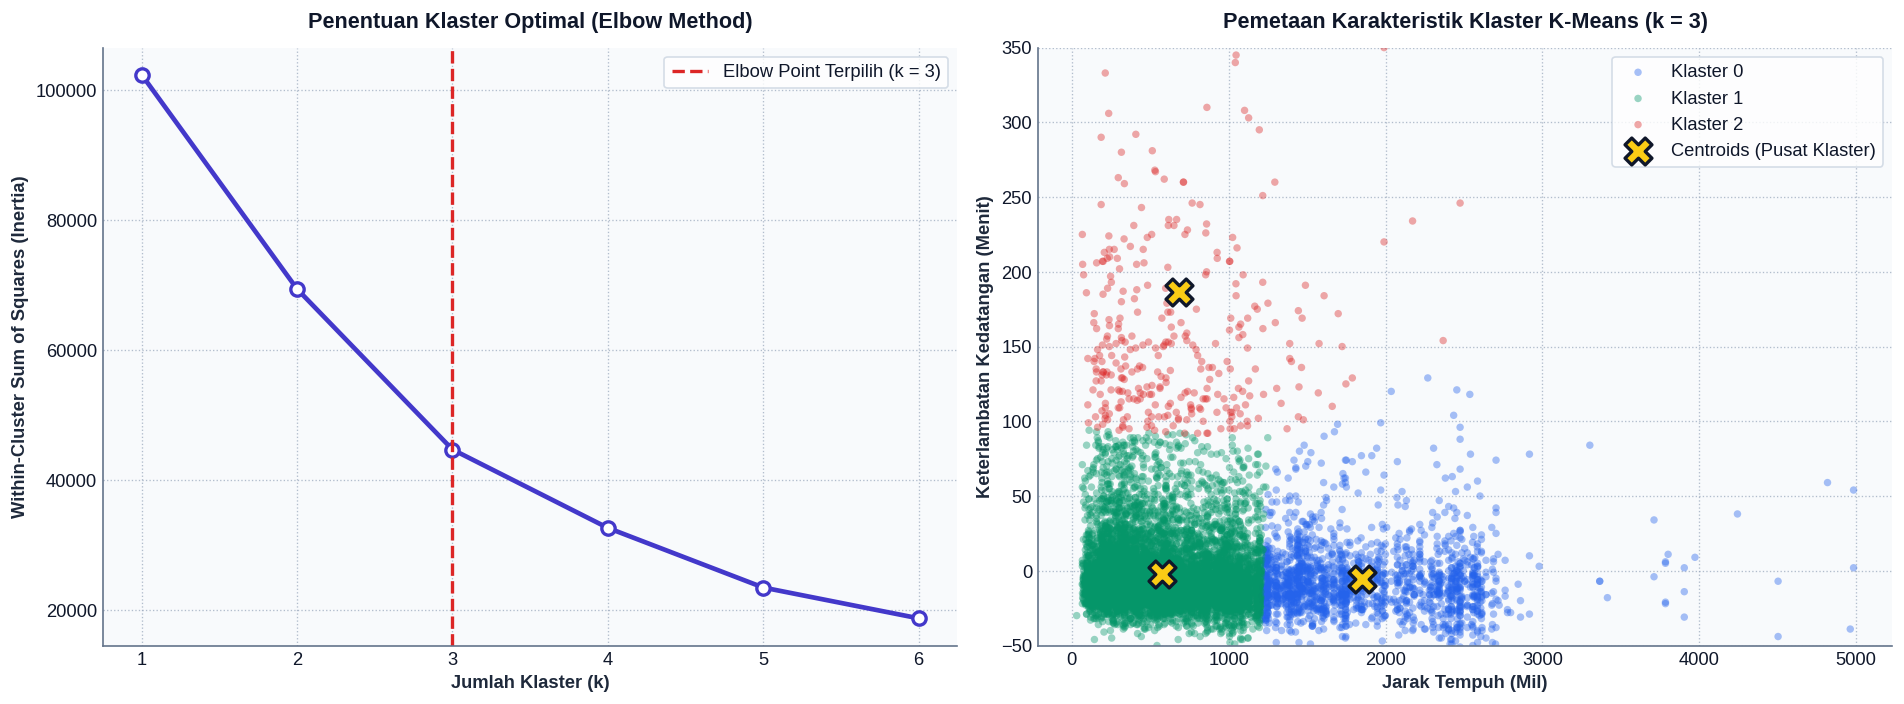

✅ Visualisasi K-Means berhasil dibuat dan disimpan.


In [14]:
# =======================================================
# 5. STANDARISASI, ELBOW METHOD & K-MEANS
# =======================================================
# 1. Standarisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_clean[['DISTANCE', 'ARR_DELAY']])

# 2. Evaluasi Elbow Method
sample_idx = np.random.choice(len(df_clean), size=min(50000, len(df_clean)), replace=False)
X_elbow = X_scaled[sample_idx]

wcss = []
k_range = range(1, 7)
for k in k_range:
    km_test = KMeans(n_clusters=k, random_state=42, n_init=5)
    km_test.fit(X_elbow)
    wcss.append(km_test.inertia_)

# 3. Fit K-Means Utama (k = 3)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=5)
df_clean['Cluster'] = kmeans.fit_predict(X_scaled)

# 4. Mengembalikan Centroid ke Skala Asli
centroids_asli = scaler.inverse_transform(kmeans.cluster_centers_)

# 5. Profil Masing-Masing Klaster
profil_klaster = []
for i in range(3):
    sub = df_clean[df_clean['Cluster'] == i]
    profil_klaster.append({
        'Klaster': f'Klaster {i}',
        'Jumlah Data': f"{len(sub):,} ({len(sub)/len(df_clean)*100:.2f}%)",
        'Centroid Distance (Mil)': f"{centroids_asli[i][0]:.2f}",
        'Centroid ARR_DELAY (Menit)': f"{centroids_asli[i][1]:.2f}",
        'Karakteristik Operasional': (
            'Rute Jarak Jauh / Transkontinental On-Time' if centroids_asli[i][0] > 1500 else
            'Kejadian Krisis / Delay Operasional Ekstrem' if centroids_asli[i][1] > 50 else
            'Rute Pendek-Menengah Reguler On-Time'
        )
    })

df_profil_klaster = pd.DataFrame(profil_klaster)

# Styling Tabel Profil K-Means (Kompatibel Dark Mode & Light Mode)
styled_klaster = (
    df_profil_klaster.style
    .set_caption("TABEL 3. KARAKTERISTIK DAN CENTROID KLASTER K-MEANS (k = 3)")
    .set_properties(subset=['Klaster', 'Jumlah Data'], **{
        'text-align': 'center', 'font-size': '13px', 'padding': '10px 14px', 'color': '#0f172a'
    })
    .set_properties(subset=['Centroid Distance (Mil)', 'Centroid ARR_DELAY (Menit)'], **{
        'text-align': 'right', 'font-size': '13px', 'font-family': 'monospace', 'font-weight': '600', 'padding': '10px 14px', 'color': '#0f172a'
    })
    .set_properties(subset=['Karakteristik Operasional'], **{
        'text-align': 'left', 'font-size': '13px', 'font-weight': '600', 'padding': '10px 14px', 'color': '#1e3a8a'
    })
    .set_table_styles([
        {'selector': 'caption', 'props': [
            ('caption-side', 'top'),
            ('font-size', '15px'),
            ('font-weight', '700'),
            ('margin-bottom', '12px'),
            ('color', '#38bdf8'),
            ('text-align', 'left')
        ]},
        {'selector': 'th', 'props': [
            ('background-color', '#312e81'),
            ('color', '#ffffff'),
            ('font-weight', '700'),
            ('padding', '11px 16px'),
            ('text-align', 'center'),
            ('border', 'none')
        ]},
        {'selector': 'tbody tr:nth-child(odd) td', 'props': [
            ('background-color', '#ffffff'),
            ('border-bottom', '1px solid #e2e8f0')
        ]},
        {'selector': 'tbody tr:nth-child(even) td', 'props': [
            ('background-color', '#f1f5f9'),
            ('border-bottom', '1px solid #e2e8f0')
        ]},
        {'selector': 'tbody tr:hover td', 'props': [
            ('background-color', '#e0e7ff')
        ]}
    ])
    .hide(axis='index')
)

display(styled_klaster)

# 6. Visualisasi Elbow Curve & Scatter Plot Klaster
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.patch.set_facecolor('#ffffff')

# Plot Elbow Method
axes[0].plot(k_range, wcss, marker='o', linewidth=2.8, color='#4338ca', markersize=8, markerfacecolor='#ffffff', markeredgewidth=2)
axes[0].set_title('Penentuan Klaster Optimal (Elbow Method)', fontsize=13, fontweight='bold', pad=12, color='#0f172a')
axes[0].set_xlabel('Jumlah Klaster (k)', fontweight='bold', color='#1e293b')
axes[0].set_ylabel('Within-Cluster Sum of Squares (Inertia)', fontweight='bold', color='#1e293b')
axes[0].axvline(3, color='#dc2626', linestyle='--', linewidth=2, label='Elbow Point Terpilih (k = 3)')
axes[0].legend(frameon=True, facecolor='#ffffff', edgecolor='#cbd5e1', labelcolor='#0f172a')

# Scatter Plot Klaster K-Means
palet_klaster = {0: '#2563eb', 1: '#059669', 2: '#dc2626'}
sub_plot = df_clean.sample(n=min(10000, len(df_clean)), random_state=42)

for c_id in sorted(df_clean['Cluster'].unique()):
    c_pts = sub_plot[sub_plot['Cluster'] == c_id]
    axes[1].scatter(c_pts['DISTANCE'], c_pts['ARR_DELAY'],
                    alpha=0.4, s=20, color=palet_klaster.get(c_id, '#64748b'),
                    label=f'Klaster {c_id}', edgecolors='none')

# Plot Centroids
axes[1].scatter(centroids_asli[:, 0], centroids_asli[:, 1],
                s=260, c='#facc15', marker='X', edgecolor='#0f172a', linewidth=2,
                label='Centroids (Pusat Klaster)', zorder=6)

axes[1].set_title('Pemetaan Karakteristik Klaster K-Means (k = 3)', fontsize=13, fontweight='bold', pad=12, color='#0f172a')
axes[1].set_xlabel('Jarak Tempuh (Mil)', fontweight='bold', color='#1e293b')
axes[1].set_ylabel('Keterlambatan Kedatangan (Menit)', fontweight='bold', color='#1e293b')
axes[1].set_ylim(-50, 350)
axes[1].legend(frameon=True, facecolor='#ffffff', edgecolor='#cbd5e1', loc='upper right', labelcolor='#0f172a')

# Mengatur tampilan grid dan border canvas
for ax in axes:
    ax.set_facecolor('#f8fafc')
    ax.grid(True, linestyle=':', alpha=0.7, color='#94a3b8')
    ax.tick_params(colors='#0f172a')
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    for spine in ['left', 'bottom']:
        ax.spines[spine].set_color('#64748b')

plt.tight_layout()
plt.savefig('kmeans_clustering_result.png', dpi=300, bbox_inches='tight')
plt.show()
print('✅ Visualisasi K-Means berhasil dibuat dan disimpan.')


### **7. Kesimpulan Karakteristik & Ringkasan Temuan**

Berdasarkan seluruh tahapan analisis statistika deskriptif dan pemodelan K-Means yang telah dilakukan, dapat ditarik beberapa kesimpulan akademis utama:

1. **Analisis Pusat & Sebaran Data:**
   * Sebagian besar operasional penerbangan berjalan sangat efisien. Hal ini ditunjukkan oleh median keterlambatan kedatangan (`ARR_DELAY`) yang bernilai negatif ($-7.00$ menit), menandakan pesawat mendarat lebih awal dari jadwal.
   * Terdapat deviasi ekstrem dengan nilai kemiringan positif yang tinggi (*skewness* = $9.07$), disebabkan oleh segelintir penerbangan yang mengalami keterlambatan parah hingga maksimal $2.455$ menit.

2. **Karakteristik Geografis Rute:**
   * Mayoritas penerbangan domestik didominasi oleh rute jarak pendek hingga menengah dengan nilai tengah (*median*) jarak tempuh sebesar $634$ mil.

3. **Segmentasi Klaster K-Means ($k = 3$):**
   * **Klaster 1 (Reguler & Tepat Waktu - $\approx 79.7\%$):** Kelompok rute jarak pendek-menengah dengan performa ketepatan waktu yang sangat andal dan stabil.
   * **Klaster 0 (Transkontinental - $\approx 17.0\%$):** Kelompok penerbangan jarak jauh yang efisien, di mana potensi keterlambatan dapat diredam dengan optimal oleh fleksibilitas waktu jelajah udara (*airtime buffer*).
   * **Klaster 2 (Krisis Operasional Ekstrem - $\approx 3.3\%$):** Kelompok penerbangan dengan keterlambatan masif ($>180$ menit). Segmentasi ini sangat krusial bagi tim operasional maskapai (IoT & Jaringan) untuk memprioritaskan pemeliharaan preventif dan optimalisasi alokasi gerbang (*gate management*).